# 03 - Pairwise Transfer Learning Matrix

**Goal**: Quantify transfer learning between every pair of organisms.

For each pair (src -> tgt) we measure:
- `delta_target`: did fine-tuning help the target organism?
- `delta_source`: did fine-tuning hurt the source organism (catastrophic forgetting)?
- `transfer_score = delta_target + min(delta_source, 0)` — the joint metric used for clustering.

**Pre-requisite**: Run `python experiments/transfer/run_experiments.py` from repo root.

In [9]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

_here = Path().resolve()
REPO_ROOT = next(p for p in [_here, *_here.parents] if (p / 'Cargo.toml').exists())

RESULTS_DIR = REPO_ROOT / 'experiments' / 'transfer' / 'results'
CONFIG_PATH = REPO_ROOT / 'experiments' / 'transfer' / 'config' / 'organisms.yaml'

sys.path.insert(0, str(REPO_ROOT / 'ml' / 'experiments'))

from utils.results_io import (
    collect_solo_evals,
    collect_finetune_evals,
    build_transfer_matrix,
    load_training_history,
)
from utils.plot_helpers import plot_transfer_heatmap, plot_training_curves

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f)

organisms = config['organisms']
names     = list(organisms.keys())
labels    = [organisms[n]['label'] for n in names]

print('REPO_ROOT:', REPO_ROOT)
print('Organisms:', names)

REPO_ROOT: /home/ziutek/fstudies/inz/dna-assembler-ml
Organisms: ['ecoli', 'cerevisiae', 'bsubtilis', 'mtuberculosis', 'hpylori']


## 1 - Solo baseline: each model on its own organism

In [10]:
solo_df = collect_solo_evals(RESULTS_DIR, names)

if solo_df.empty:
    print('No solo results found. Run the experiments first.')
else:
    baseline = solo_df[solo_df['model_organism'] == solo_df['eval_organism']].copy()
    baseline = baseline.set_index('model_organism')[['junction_accuracy', 'pair_accuracy', 'f1', 'n_junctions']]
    baseline.columns = ['junc_acc', 'pair_acc', 'F1', 'n_junctions']
    display(baseline.style.format('{:.4f}', subset=['junc_acc', 'pair_acc', 'F1']).background_gradient(
        subset=['junc_acc'], cmap='RdYlGn', vmin=0.5, vmax=1.0))

,junc_acc,pair_acc,F1,n_junctions
model_organism,,,,
ecoli,0.7000,0.7279,0.8425,130
cerevisiae,0.6476,0.6651,0.7989,593
bsubtilis,0.6000,0.6000,0.7500,25
mtuberculosis,0.5723,0.5787,0.7331,173
hpylori,0.6316,0.6500,0.7879,38


## 2 - Zero-shot cross-evaluation

Accuracy of each solo model when evaluated on a *different* organism (no fine-tuning).

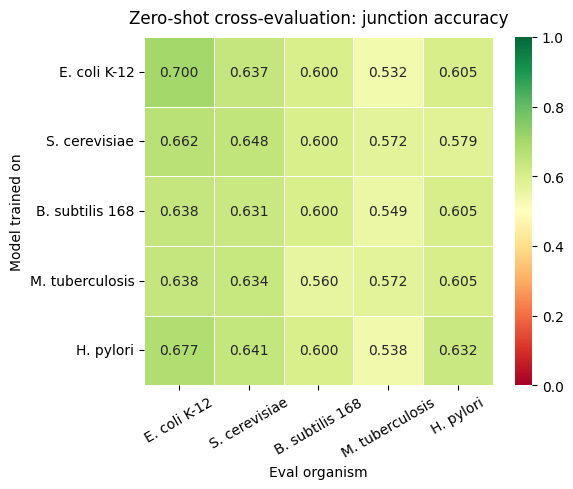

In [11]:
if not solo_df.empty:
    pivot = solo_df.pivot(index='model_organism', columns='eval_organism', values='junction_accuracy')
    pivot = pivot.reindex(index=names, columns=names)

    fig, ax = plt.subplots(figsize=(len(names) + 1, len(names)))
    plot_transfer_heatmap(
        pivot.values,
        labels=labels,
        title='Zero-shot cross-evaluation: junction accuracy',
        ax=ax,
        vmin=0.0, vmax=1.0,
        center=0.5,
    )
    ax.set_xlabel('Eval organism')
    ax.set_ylabel('Model trained on')
    plt.tight_layout()
    plt.show()

## 3 - Fine-tune delta: did fine-tuning help the target?

`delta_target[src, tgt] = acc(model_src fine-tuned on tgt, evaluated on tgt) − acc(model_tgt solo on tgt)`

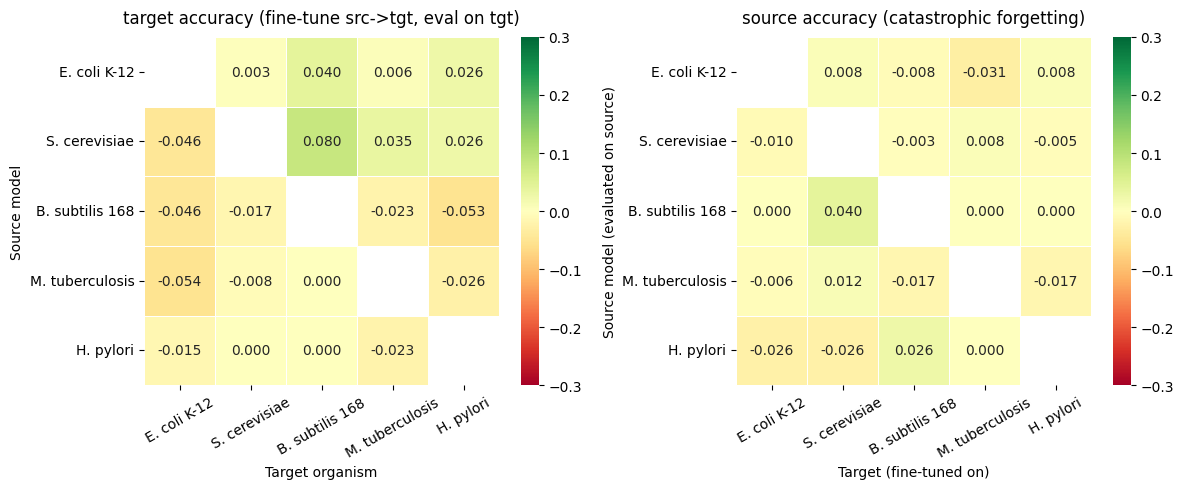

In [12]:
ft_df = collect_finetune_evals(RESULTS_DIR, names)

if ft_df.empty:
    print('No fine-tune results found. Run the experiments first.')
else:
    solo_self_acc = {
        row['model_organism']: row['junction_accuracy']
        for _, row in solo_df[solo_df['model_organism'] == solo_df['eval_organism']].iterrows()
    }

    n = len(names)
    delta_tgt = np.full((n, n), np.nan)
    delta_src = np.full((n, n), np.nan)

    for i, src in enumerate(names):
        for j, tgt in enumerate(names):
            if src == tgt:
                continue
            ft_on_tgt = ft_df[
                (ft_df['source_organism'] == src) &
                (ft_df['target_organism'] == tgt) &
                (ft_df['eval_organism']   == tgt)
            ]
            ft_on_src = ft_df[
                (ft_df['source_organism'] == src) &
                (ft_df['target_organism'] == tgt) &
                (ft_df['eval_organism']   == src)
            ]
            if not ft_on_tgt.empty and tgt in solo_self_acc:
                delta_tgt[i, j] = ft_on_tgt.iloc[0]['junction_accuracy'] - solo_self_acc[tgt]
            if not ft_on_src.empty and src in solo_self_acc:
                delta_src[i, j] = ft_on_src.iloc[0]['junction_accuracy'] - solo_self_acc[src]

    fig, axes = plt.subplots(1, 2, figsize=(2 * (len(names) + 1), len(names)))

    plot_transfer_heatmap(delta_tgt, labels,
                          title='target accuracy (fine-tune src->tgt, eval on tgt)',
                          ax=axes[0], vmin=-0.3, vmax=0.3)
    axes[0].set_xlabel('Target organism')
    axes[0].set_ylabel('Source model')

    plot_transfer_heatmap(delta_src, labels,
                          title='source accuracy (catastrophic forgetting)',
                          ax=axes[1], vmin=-0.3, vmax=0.3)
    axes[1].set_xlabel('Target (fine-tuned on)')
    axes[1].set_ylabel('Source model (evaluated on source)')

    plt.tight_layout()
    plt.show()

## 4 - Joint transfer score matrix

`transfer_score[src, tgt] = delta_target + min(delta_source, 0)`

Positive = fine-tuning src on tgt was a net win.  
Negative = fine-tuning either hurt the target or caused strong forgetting.

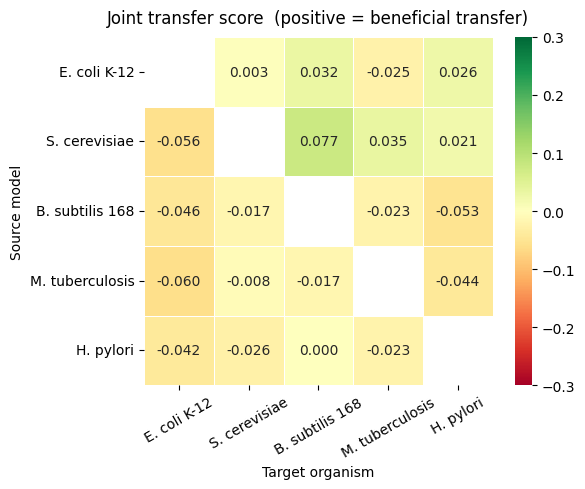

Transfer matrix saved to /home/ziutek/fstudies/inz/dna-assembler-ml/experiments/transfer/results/transfer_matrix.npy


In [13]:
if not ft_df.empty:
    transfer_matrix = build_transfer_matrix(ft_df, solo_df, names)

    fig, ax = plt.subplots(figsize=(len(names) + 1, len(names)))
    plot_transfer_heatmap(
        transfer_matrix,
        labels=labels,
        title='Joint transfer score  (positive = beneficial transfer)',
        ax=ax,
        vmin=-0.3, vmax=0.3,
    )
    ax.set_xlabel('Target organism')
    ax.set_ylabel('Source model')
    plt.tight_layout()
    plt.show()

    # Save for notebook 04
    np.save(RESULTS_DIR / 'transfer_matrix.npy', transfer_matrix)
    pd.DataFrame(transfer_matrix, index=names, columns=names).to_csv(
        RESULTS_DIR / 'transfer_matrix.csv')
    print('Transfer matrix saved to', RESULTS_DIR / 'transfer_matrix.npy')

## 5 - Training curves for selected pairs

Inspect learning dynamics for the most interesting (best and worst) transfer pairs.

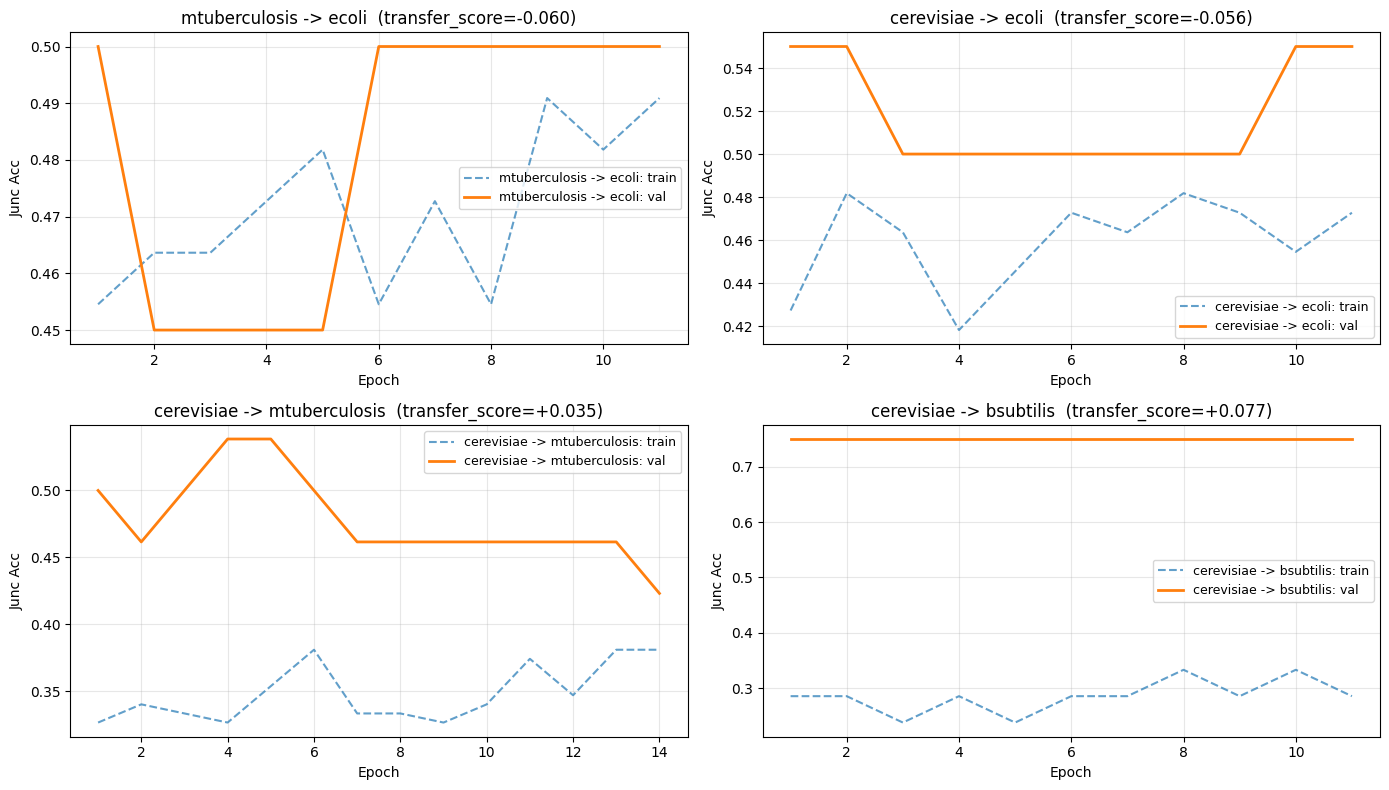

In [14]:
if not ft_df.empty:
    flat_scores = [
        (transfer_matrix[i, j], names[i], names[j])
        for i in range(len(names)) for j in range(len(names))
        if not np.isnan(transfer_matrix[i, j])
    ]
    flat_scores.sort()

    # Best and worst 2 pairs
    to_plot = flat_scores[:2] + flat_scores[-2:]

    fig, axes = plt.subplots(2, 2, figsize=(14, 8))
    for ax, (score, src, tgt) in zip(axes.flat, to_plot):
        ft_dir = RESULTS_DIR / 'finetune' / f'{src}_to_{tgt}'
        hist = load_training_history(ft_dir)
        plot_training_curves(
            hist, ax=ax,
            label_prefix=f'{src} -> {tgt}: ',
        )
        ax.set_title(f'{src} -> {tgt}  (transfer_score={score:+.3f})')

    plt.tight_layout()
    plt.show()